In [ ]:
!pip install imbalanced-learn

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import RandomOverSampler


In [ ]:
from google.colab import files

uploaded = files.upload()
### Dataset :- https://www.kaggle.com/datasets/yasserh/titanic-dataset

Saving Titanic-Dataset.csv to Titanic-Dataset.csv


In [ ]:
## Task 1
df = pd.read_csv("Titanic-Dataset.csv")
print("Dataset Loaded Successfully")
df.head()
df.info()
df.describe()


Dataset Loaded Successfully
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
## Task 2
print("Rows and Columns :", df.shape)

print("\nColumns\n")
print(df.columns)

print("\nData Types\n")
print(df.dtypes)

print("\nMissing Values\n")
print(df.isnull().sum())

Rows and Columns : (1628, 9)

Columns

Index(['title', 'year', 'tmdb_id', 'actor_name', 'character', 'cast_order',
       'actor_tmdb_id', 'popularity', 'profile_path'],
      dtype='object')

Data Types

title             object
year               int64
tmdb_id          float64
actor_name        object
character         object
cast_order         int64
actor_tmdb_id      int64
popularity       float64
profile_path      object
dtype: object

Missing Values

title             0
year              0
tmdb_id           0
actor_name        0
character        10
cast_order        0
actor_tmdb_id     0
popularity        0
profile_path     90
dtype: int64


In [ ]:
## Task 3

print("First Five Records")
display(df.head())

print("\nLast Five Records")
display(df.tail())

print("\nRandom Records")
display(df.sample(5))

First Five Records


,title,year,tmdb_id,actor_name,character,cast_order,actor_tmdb_id,popularity,profile_path
0,Captain America,1944,106355.0,Dick Purcell,Captain America / Grant Gardner,0,13970,0.3970,https://image.tmdb.org/t/p/w185/p0RZAW7uh1dIwu...
1,Captain America,1944,106355.0,Lorna Gray,Gail Richards,1,96719,0.4055,https://image.tmdb.org/t/p/w185/cdWxxF7weiJucc...
2,Captain America,1944,106355.0,Lionel Atwill,Cyrus Maldor,2,2495,0.4445,https://image.tmdb.org/t/p/w185/2KFwXY3fsMWWye...
3,Captain America,1944,106355.0,Charles Trowbridge,Police Commissioner Dryden,3,96721,0.3023,https://image.tmdb.org/t/p/w185/l0pMZJiTfkxBOE...
4,Captain America,1944,106355.0,Russell Hicks,Mayor Randolph,4,13969,0.8038,https://image.tmdb.org/t/p/w185/5Pir7aPr3Iooqd...



Last Five Records


,title,year,tmdb_id,actor_name,character,cast_order,actor_tmdb_id,popularity,profile_path
1623,Spider-Man: Brand New Day,2026,969681.0,Eman Esfandi,NaN,10,2243207,0.3494,https://image.tmdb.org/t/p/w185/lrDfNC81vTkFW9...
1624,Spider-Man: Brand New Day,2026,969681.0,Keith David,NaN,11,65827,2.0395,https://image.tmdb.org/t/p/w185/1x0QXavmIy3Qmh...
1625,Spider-Man: Brand New Day,2026,969681.0,Zabryna Guevara,Sheila Rivera,12,171955,0.7338,https://image.tmdb.org/t/p/w185/7NlCmTZoauvyqj...
1626,Spider-Man: Brand New Day,2026,969681.0,Rosario Dawson,Claire Temple,13,5916,2.3905,https://image.tmdb.org/t/p/w185/1mm7JGHIUX3GRR...
1627,Spider-Man: Brand New Day,2026,969681.0,Marisa Tomei,May Parker,14,3141,2.7640,https://image.tmdb.org/t/p/w185/5w6qM8FWsl5Sut...



Random Records


,title,year,tmdb_id,actor_name,character,cast_order,actor_tmdb_id,popularity,profile_path
1490,Agatha All Along,2024,1387507.0,Daniel Selon,Self - Costume Designer,3,1423256,0.1354,https://image.tmdb.org/t/p/w185/9bsTiS13Bhuktr...
1132,Black Widow,2021,497698.0,Rachel Weisz,Melina,2,3293,4.0183,https://image.tmdb.org/t/p/w185/9tfHL5tholha1Y...
741,Guardians of the Galaxy,2014,118340.0,Chris Pratt,Peter Quill,0,73457,5.1610,https://image.tmdb.org/t/p/w185/872Hzdq95gsbMR...
1542,Thunderbolts*,2025,986056.0,Violet McGraw,Young Yelena,11,2131391,1.3238,https://image.tmdb.org/t/p/w185/zxY8BRNRYUFikW...
38,Spider-Man,1977,225914.0,Ivor Francis,Prof. Noah Tyler,10,84327,0.4057,https://image.tmdb.org/t/p/w185/yFSyIq7SdLqcCC...


In [ ]:
## Task 4
print(df.isnull().sum())
df["Age"] = df["Age"].fillna(df["Age"].mean())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df.drop("Cabin", axis=1, inplace=True, errors="ignore")
print("\n",df.isnull().sum())


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

 PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [ ]:
## Task 5:
print("Duplicate Rows :", df.duplicated().sum())

df.drop_duplicates(inplace=True)

print("Duplicates After Removing :", df.duplicated().sum())

Duplicate Rows : 0
Duplicates After Removing : 0


     PassengerId  Survived  Pclass  \
1              2         1       1   
27            28         0       1   
31            32         1       1   
34            35         0       1   
52            53         1       1   
..           ...       ...     ...   
846          847         0       3   
849          850         1       1   
856          857         1       1   
863          864         0       3   
879          880         1       1   

                                                  Name     Sex        Age  \
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.000000   
27                      Fortune, Mr. Charles Alexander    male  19.000000   
31      Spencer, Mrs. William Augustus (Marie Eugenie)  female  29.699118   
34                             Meyer, Mr. Edgar Joseph    male  28.000000   
52            Harper, Mrs. Henry Sleeper (Myna Haxtun)  female  49.000000   
..                                                 ...     ...        ...   
846 

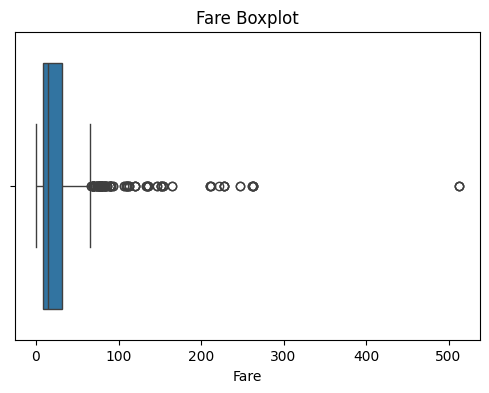

In [ ]:
## Task 6:
Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)

IQR = Q3-Q1

lower = Q1-1.5*IQR
upper = Q3+1.5*IQR

outliers = df[(df["Fare"]<lower) | (df["Fare"]>upper)]

print(outliers)

plt.figure(figsize=(6,4))
sns.boxplot(x=df["Fare"])
plt.title("Fare Boxplot")
plt.show()

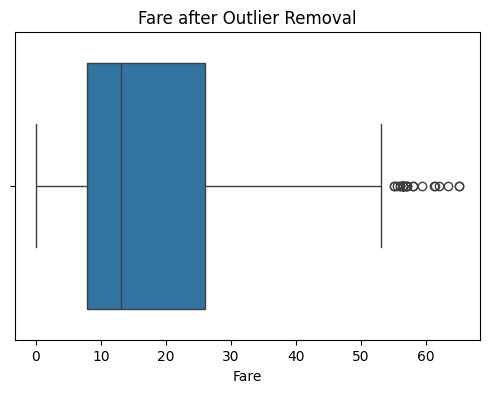

In [ ]:
## Task 7
df = df[(df["Fare"] >= lower) & (df["Fare"] <= upper)].copy()

plt.figure(figsize=(6,4))
sns.boxplot(x=df["Fare"])
plt.title("Fare after Outlier Removal")
plt.show()

In [ ]:
## Task 8:
##Label Encoding
le = LabelEncoder()

df["Sex"] = le.fit_transform(df["Sex"])

df.head()
##One-Hot Encoding
df = pd.get_dummies(df, columns=["Embarked"], dtype=int)

df.head()



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",1,22.000000,1,0,A/5 21171,7.2500,0,0,1
2,3,1,3,"Heikkinen, Miss. Laina",0,26.000000,0,0,STON/O2. 3101282,7.9250,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.000000,1,0,113803,53.1000,0,0,1
4,5,0,3,"Allen, Mr. William Henry",1,35.000000,0,0,373450,8.0500,0,0,1
5,6,0,3,"Moran, Mr. James",1,29.699118,0,0,330877,8.4583,0,1,0


In [ ]:
## Task 9
##Min-Max Normalization
minmax = MinMaxScaler()

df["Age"] = minmax.fit_transform(df[["Age"]])
##Standardization (Z-score Scaling)
standard = StandardScaler()

df["Fare"] = standard.fit_transform(df[["Fare"]])

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",1,0.271174,1,0,A/5 21171,-0.779117,0,0,1
2,3,1,3,"Heikkinen, Miss. Laina",0,0.321438,0,0,STON/O2. 3101282,-0.729373,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,0.434531,1,0,113803,2.599828,0,0,1
4,5,0,3,"Allen, Mr. William Henry",1,0.434531,0,0,373450,-0.720161,0,0,1
5,6,0,3,"Moran, Mr. James",1,0.367921,0,0,330877,-0.690071,0,1,0


In [ ]:
## Task 10
correlation = df.select_dtypes(include=np.number).corr()

correlation["Survived"].sort_values(ascending=False)

,Survived
Survived,1.000000
Fare,0.234422
Parch,0.098575
Embarked_C,0.096513
Embarked_Q,0.032707
SibSp,-0.003156
PassengerId,-0.024438
Embarked_S,-0.102337
Age,-0.121283
Pclass,-0.238532


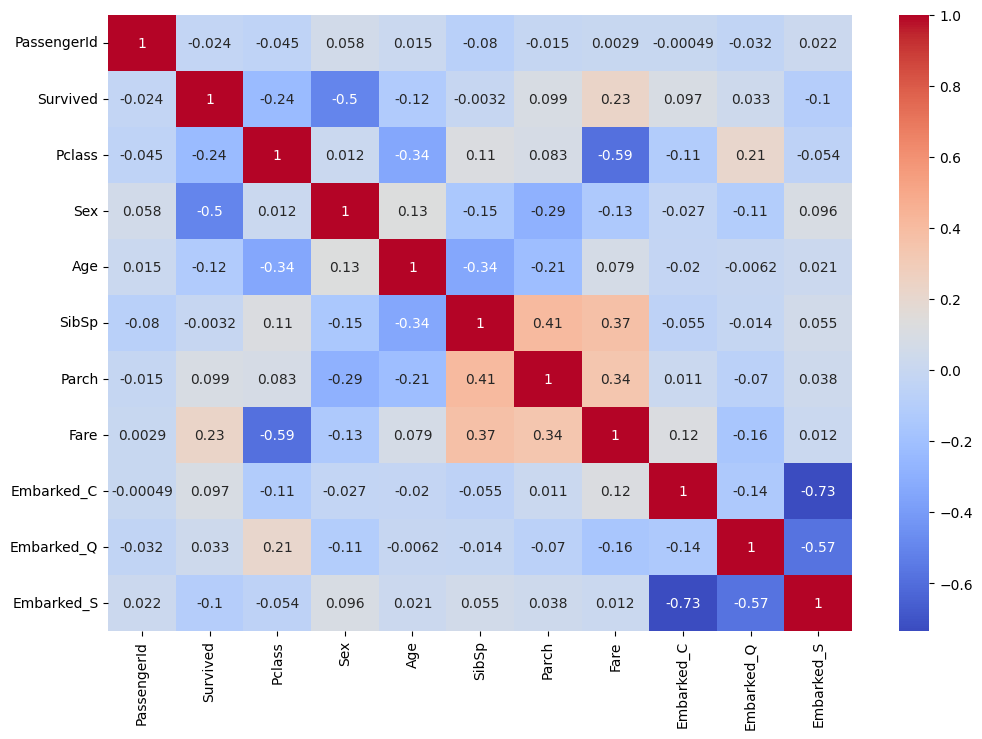

In [ ]:
## Task 11
plt.figure(figsize=(12,8))

sns.heatmap(correlation,
            annot=True,
            cmap="coolwarm")

plt.show()

In [ ]:
## Task 12:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"]==1).astype(int)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_C,Embarked_Q,Embarked_S,FamilySize,IsAlone
0,1,0,3,"Braund, Mr. Owen Harris",1,0.271174,1,0,A/5 21171,-0.779117,0,0,1,2,0
2,3,1,3,"Heikkinen, Miss. Laina",0,0.321438,0,0,STON/O2. 3101282,-0.729373,0,0,1,1,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,0.434531,1,0,113803,2.599828,0,0,1,2,0
4,5,0,3,"Allen, Mr. William Henry",1,0.434531,0,0,373450,-0.720161,0,0,1,1,1
5,6,0,3,"Moran, Mr. James",1,0.367921,0,0,330877,-0.690071,0,1,0,1,1


In [ ]:
## Task 13:
print(df.dtypes)
df["Survived"] = df["Survived"].astype(float)

print("\n",df.dtypes)


PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex              int64
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Embarked_C       int64
Embarked_Q       int64
Embarked_S       int64
FamilySize       int64
IsAlone          int64
dtype: object

 PassengerId      int64
Survived       float64
Pclass           int64
Name            object
Sex              int64
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Embarked_C       int64
Embarked_Q       int64
Embarked_S       int64
FamilySize       int64
IsAlone          int64
dtype: object


In [ ]:
## Task 14
df["Name"] = df["Name"].str.strip()

df["Ticket"] = df["Ticket"].str.upper()

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_C,Embarked_Q,Embarked_S,FamilySize,IsAlone
0,1,0.0,3,"Braund, Mr. Owen Harris",1,0.271174,1,0,A/5 21171,-0.779117,0,0,1,2,0
2,3,1.0,3,"Heikkinen, Miss. Laina",0,0.321438,0,0,STON/O2. 3101282,-0.729373,0,0,1,1,1
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,0.434531,1,0,113803,2.599828,0,0,1,2,0
4,5,0.0,3,"Allen, Mr. William Henry",1,0.434531,0,0,373450,-0.720161,0,0,1,1,1
5,6,0.0,3,"Moran, Mr. James",1,0.367921,0,0,330877,-0.690071,0,1,0,1,1


In [ ]:
## Task 15
X = df.drop("Survived", axis=1)

X = X.select_dtypes(include=np.number)

y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(620, 12)
(155, 12)


In [ ]:
## Task 16
print("Before")

print(y.value_counts())
ros = RandomOverSampler(random_state=42)

X_resampled, y_resampled = ros.fit_resample(X_train, y_train)

print("After")

print(pd.Series(y_resampled).value_counts())

Before
Survived
0.0    512
1.0    263
Name: count, dtype: int64
After
Survived
0.0    417
1.0    417
Name: count, dtype: int64


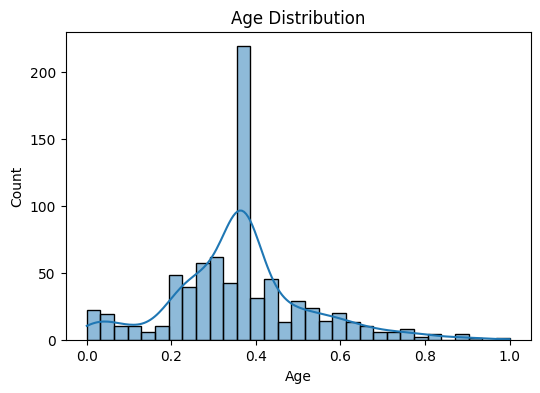

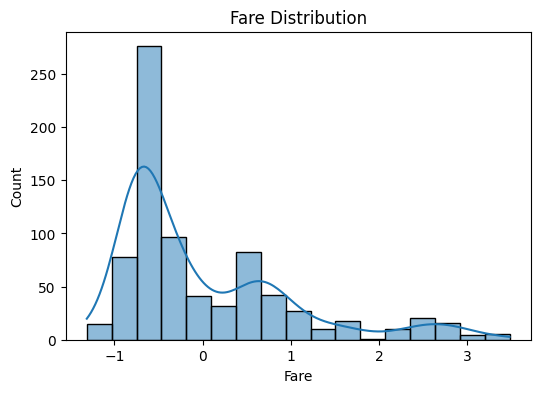

In [ ]:
## Task 17
plt.figure(figsize=(6,4))

sns.histplot(df["Age"], kde=True)

plt.title("Age Distribution")

plt.show()

plt.figure(figsize=(6,4))

sns.histplot(df["Fare"], kde=True)

plt.title("Fare Distribution")

plt.show()

In [ ]:
##Task 18
original = pd.read_csv("Titanic-Dataset.csv")

print("Original Shape :", original.shape)

print("Processed Shape :", df.shape)

comparison = pd.DataFrame({
    "Original Missing": original.isnull().sum(),
    "Processed Missing": df.isnull().sum()
})

comparison

Original Shape : (891, 12)
Processed Shape : (775, 15)


,Original Missing,Processed Missing
Age,177.0,0.0
Cabin,687.0,NaN
Embarked,2.0,NaN
Embarked_C,NaN,0.0
Embarked_Q,NaN,0.0
Embarked_S,NaN,0.0
FamilySize,NaN,0.0
Fare,0.0,0.0
IsAlone,NaN,0.0
Name,0.0,0.0


In [ ]:
## Task 19
df.to_csv("cleaned_titanic.csv", index=False)

print("Dataset Saved Successfully")
files.download("cleaned_titanic.csv")

Dataset Saved Successfully


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Task 20: Documentation of Preprocessing Steps

## Summary of Preprocessing

1. Loaded the Titanic dataset using Pandas.
2. Displayed the dataset's structure and summary statistics.
3. Identified missing values in the dataset.
4. Filled missing values in the **Age** column using the mean.
5. Filled missing values in the **Embarked** column using the mode.
6. Removed the **Cabin** column due to a large number of missing values.
7. Checked for and removed duplicate records.
8. Detected outliers in the **Fare** column using the IQR method.
9. Removed the detected outliers.
10. Converted the **Sex** column into numerical values using Label Encoding.
11. Converted the **Embarked** column using One-Hot Encoding.
12. Applied Min-Max Scaling to the **Age** feature.
13. Applied Standardization to the **Fare** feature.
14. Generated a correlation matrix and heatmap.
15. Created new features (**FamilySize** and **IsAlone**) through feature engineering.
16. Converted data types where necessary.
17. Cleaned inconsistent text data.
18. Split the dataset into training and testing sets.
19. Balanced the training dataset using Random Oversampling.
20. Saved the cleaned and preprocessed dataset as **cleaned_titanic.csv**.

### Conclusion

The dataset has been successfully preprocessed and is now suitable for machine learning tasks. Missing values, duplicates, outliers, and categorical variables were handled appropriately, numerical features were scaled, new features were created, and the dataset was prepared for model training.